# Практическая работа №2. Кварталы и метрики города: Черноголовка

**Курс:** «Технологии искусственного интеллекта в урбанистике»
**Территория:** город Черноголовка, городской округ Черноголовка, Московская область, Россия (≈ 8 км²)
**Инструмент:** библиотека [BlocksNet](https://github.com/aimclub/blocksnet) 1.0.0a9, пример `examples/pipeline.ipynb`
**Исполнитель кода:** ИИ-агент (Claude Code). По разрешению преподавателя работа целиком выполнена через ИИ: агент написал код, загрузил данные, запустил все ячейки и собрал дашборд.

## План работы

| № | Задача | Результат |
|---|---|---|
| 1 | Найти границу города | `data/boundary.geojson` и карта |
| 2 | Загрузить дороги, железные дороги и воду из OSM | `data/roads.geojson`, `data/railways.geojson`, `data/water.geojson` |
| 3 | Нарезать кварталы | `results/blocks.geojson` и карта поверх дорог и воды |
| — | **Остановка:** проверка кварталов и знакомство с метриками | таблица метрик |
| 4 | Землепользование | доли функций и преобладающая функция квартала |
| 5 | Время в пути (готовый пешеходный граф OSM, без интермодального) | матрица времени в минутах |
| 6 | Здания и оценка населения | показатели застройки по кварталам |
| 7 | Школы и их вместимость | число школ и мест, отдельная пометка оценённой вместимости |
| 8 | Обеспеченность школами | provision_strong / weak, нехватка и остатки мест, связи спроса |
| 9 | Плотность застройки | FSI, GSI, MXI, L, OSR |
| 10 | Типы застройки | Spacematrix (с характеристиками кластеров) и «Стрелка» |
| 11 | Доступность с учётом площади | средневзвешенное время до территории города |
| 12 | Сводный файл и выводы | `results/blocks_all.geojson` и дашборд `dashboard.html` (скрипт `make_dashboard.py`) |

## Основные запросы к ИИ

1. Студент: «Сделай практическую работу №2 по курсу „Технологии ИИ в урбанистике“ (ссылка на задание). Выполни все пункты, положи код, полученные файлы и выводы в папку практики».
2. Студент: «Преподаватель сказал, что если попросить полностью сделать практическую через ИИ, это круто, так что сделай полностью».
3. Логика шагов повторяет промпты из задания: Plan (составить план по `pipeline.ipynb`), Build (ноутбук, остановка после кварталов, «Какие метрики есть в BlocksNet?», расчёты всех показателей, отдельный Python-файл для `dashboard.html`, сверка с `pipeline.ipynb`).

## Как запустить заново

1. Откройте папку проекта в VS Code и терминал **Command Prompt**.
2. Активируйте окружение: `.venv\Scripts\activate.bat`.
3. Откройте этот ноутбук, выберите ядро Python из `.venv` и нажмите **Run All**.
   Уже скачанные файлы из `data/` и `results/` читаются повторно, интернет для расчётов не нужен.
   Чтобы скачать всё заново, поставьте `REFRESH = True` в первой ячейке кода.
4. Соберите страницу: `python make_dashboard.py`. Откройте `dashboard.html` в браузере.

In [1]:
import warnings
import json
import pickle
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import osmnx as ox
import blocksnet

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (9, 9)

# Территория исследования. Регион и страна указаны, чтобы не перепутать с другими населёнными пунктами.
PLACE = "Черноголовка, Московская область, Россия"

DATA_DIR = Path("data")        # исходные данные (OpenStreetMap)
RESULTS_DIR = Path("results")  # результаты расчётов
for folder in (DATA_DIR, RESULTS_DIR):
    folder.mkdir(exist_ok=True)

# False — читать готовые файлы, если они уже есть; True — скачать и пересчитать всё заново
REFRESH = False

# Откуда брать пешеходный граф:
#   "osm_extract" — собрать OSMnx из той же выгрузки OSM, что и остальные слои (работает всегда);
#   "iduedu"      — скачать готовый walk-граф IduEdu через Overpass API (как get_accessibility_graph в BlocksNet).
GRAPH_SOURCE = "osm_extract"
WALK_SPEED_KMH = 5  # скорость пешехода, как в IduEdu

print("BlocksNet", blocksnet.__version__ if hasattr(blocksnet, "__version__") else "1.0.0a9")
print("osmnx", ox.__version__)

BlocksNet 1.0.0a9
osmnx 2.1.1


### Вспомогательные функции

`load_or_fetch` — главный приём повторного использования: если GeoJSON уже лежит в папке, он читается с диска, иначе данные скачиваются и сохраняются.
Все слои хранятся в GeoJSON в координатах WGS 84 (EPSG:4326), а для расчётов переводятся в метрическую проекцию UTM.
Дата загрузки каждого слоя записывается в `data/sources.json`.

In [2]:
SOURCES_FILE = DATA_DIR / "sources.json"
sources = json.loads(SOURCES_FILE.read_text(encoding="utf-8")) if SOURCES_FILE.exists() else {}


def save_geojson(gdf: gpd.GeoDataFrame, path: Path) -> None:
    gdf = gdf.copy()
    for col in gdf.columns:
        if col != "geometry" and gdf[col].dtype == object:
            gdf[col] = gdf[col].apply(lambda v: v if v is None or isinstance(v, (str, int, float, bool)) else str(v))
    gdf.to_crs(4326).to_file(path, driver="GeoJSON")


def load_or_fetch(name: str, fetch, source: str, folder: Path = DATA_DIR) -> gpd.GeoDataFrame:
    path = folder / f"{name}.geojson"
    if path.exists() and not REFRESH:
        gdf = gpd.read_file(path)
        print(f"✔ {name}: прочитано из {path} — {len(gdf)} объектов")
    else:
        gdf = fetch()
        save_geojson(gdf, path)
        sources[name] = {"source": source, "downloaded": datetime.date.today().isoformat(), "count": len(gdf)}
        SOURCES_FILE.write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding="utf-8")
        print(f"⬇ {name}: загружено ({source}) и сохранено в {path} — {len(gdf)} объектов")
    if len(gdf) == 0:
        print(f"⚠ {name}: объектов нет — слой пустой, расчёт продолжится без него")
    return gdf


def osm_features(tags: dict, keep: list[str]) -> gpd.GeoDataFrame:
    # Достаёт объекты с нужными тегами из сохранённой выгрузки OSM, обрезая их по границе города
    try:
        gdf = ox.features_from_xml(OSM_FILE, polygon=polygon_4326, tags=tags).reset_index()
    except ox._errors.InsufficientResponseError:
        return gpd.GeoDataFrame(columns=keep + ["geometry"], geometry="geometry", crs=4326)
    cols = [c for c in keep if c in gdf.columns]
    return gdf[cols + ["geometry"]].copy()

## 1. Граница территории

Границу берём из OpenStreetMap через геокодер Nominatim (`osmnx.geocode_to_gdf`). Это административная граница **города** Черноголовка (не всего городского округа: в округ входят ещё леса и сёла, ≈ 62 км²).

⬇ boundary: загружено (OpenStreetMap / Nominatim) и сохранено в data\boundary.geojson — 1 объектов
Chernogolovka, городской округ Черноголовка, Moscow Oblast, Central Federal District, 142432, Russia
Проекция для расчётов: WGS 84 / UTM zone 37N; площадь территории: 8.05 км²


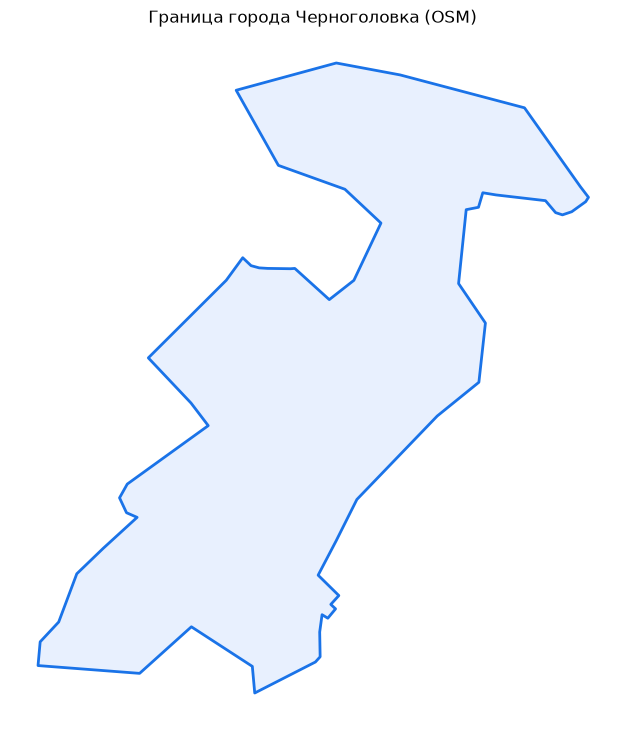

In [3]:
boundaries = load_or_fetch(
    "boundary",
    lambda: ox.geocode_to_gdf(PLACE)[["display_name", "geometry"]],
    source="OpenStreetMap / Nominatim",
)
crs = boundaries.estimate_utm_crs()
boundaries = boundaries.to_crs(crs)
polygon_4326 = boundaries.to_crs(4326).union_all()

print(boundaries.display_name.iloc[0])
print(f"Проекция для расчётов: {crs.name}; площадь территории: {boundaries.area.sum() / 1e6:.2f} км²")
ax = boundaries.plot(color="#e8f0fe", edgecolor="#1a73e8", linewidth=2)
ax.set_title("Граница города Черноголовка (OSM)")
ax.set_axis_off()

### Выгрузка OpenStreetMap

Все слои (дороги, вода, землепользование, здания, школы, пешеходная сеть) берутся из **одной выгрузки OSM**, скачанной через официальный API OpenStreetMap (`api.openstreetmap.org/api/0.6/map`). Рамка города разбита на 12 небольших прямоугольников (лимит API), куски объединены в файл `data/chernogolovka.osm`.

Почему не Overpass API, как в `pipeline.ipynb`: в момент выполнения работы все публичные серверы Overpass (overpass-api.de и зеркала) отвечали ошибками перегрузки (406/500/502/504). Данные те же самые, отличается только способ скачивания. Граница уже получена через Nominatim.

In [4]:
import time
import requests
import xml.etree.ElementTree as ET

OSM_FILE = DATA_DIR / "chernogolovka.osm"


def download_osm_extract(bounds, path: Path, dx: float = 0.025, dy: float = 0.012) -> None:
    minx, miny, maxx, maxy = bounds[0] - 0.003, bounds[1] - 0.002, bounds[2] + 0.003, bounds[3] + 0.002
    elements = {"node": {}, "way": {}, "relation": {}}
    for x in np.arange(minx, maxx, dx):
        for y in np.arange(miny, maxy, dy):
            bbox = f"{x:.5f},{y:.5f},{min(x + dx, maxx):.5f},{min(y + dy, maxy):.5f}"
            for attempt in range(4):
                r = requests.get("https://api.openstreetmap.org/api/0.6/map", params={"bbox": bbox},
                                 headers={"User-Agent": "urban-ai-practice-02/1.0 (student study project)"}, timeout=180)
                if r.ok:
                    break
                time.sleep(5 * (attempt + 1))
            r.raise_for_status()
            for el in ET.fromstring(r.content):
                if el.tag in elements:
                    elements[el.tag][el.get("id")] = el  # объекты на стыке кусков не дублируются
    root = ET.Element("osm", version="0.6", generator="practice02")
    for group in elements.values():
        root.extend(group.values())
    ET.ElementTree(root).write(path, encoding="utf-8", xml_declaration=True)
    print({k: len(v) for k, v in elements.items()})


if OSM_FILE.exists() and not REFRESH:
    print(f"✔ выгрузка OSM прочитана из {OSM_FILE} ({OSM_FILE.stat().st_size / 1e6:.1f} МБ)")
else:
    download_osm_extract(boundaries.to_crs(4326).total_bounds, OSM_FILE)
    sources["osm_extract"] = {"source": "OpenStreetMap API 0.6 /map (© участники OpenStreetMap, ODbL)",
                              "downloaded": datetime.date.today().isoformat()}
    SOURCES_FILE.write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"⬇ выгрузка OSM сохранена в {OSM_FILE} ({OSM_FILE.stat().st_size / 1e6:.1f} МБ)")

{'node': 16690, 'way': 2537, 'relation': 93}
⬇ выгрузка OSM сохранена в data\chernogolovka.osm (4.4 МБ)


## 2. Дороги, железные дороги и вода

Теги OSM взяты из `pipeline.ipynb` без изменений. Эти линии и полигоны служат «ножами», которыми территория режется на кварталы.

In [5]:
bc_tags = {
    "roads": {
        "highway": ["construction", "crossing", "living_street", "motorway", "motorway_link", "motorway_junction",
                    "pedestrian", "primary", "primary_link", "raceway", "residential", "road", "secondary",
                    "secondary_link", "services", "tertiary", "tertiary_link", "track", "trunk", "trunk_link",
                    "turning_circle", "turning_loop", "unclassified"],
        "service": ["living_street", "emergency_access"],
    },
    "railways": {"railway": "rail"},
    "water": {
        "riverbank": True, "reservoir": True, "basin": True, "dock": True, "canal": True, "pond": True,
        "natural": ["water", "bay"], "waterway": ["river", "canal", "ditch"], "landuse": "basin", "water": "lake",
    },
}

roads = load_or_fetch("roads", lambda: osm_features(bc_tags["roads"], ["highway", "name"]), "OpenStreetMap (выгрузка API)")
railways = load_or_fetch("railways", lambda: osm_features(bc_tags["railways"], ["railway", "name"]), "OpenStreetMap (выгрузка API)")
water = load_or_fetch("water", lambda: osm_features(bc_tags["water"], ["natural", "waterway", "water", "name"]), "OpenStreetMap (выгрузка API)")

water = water[water.geom_type.isin(["Polygon", "MultiPolygon", "LineString", "MultiLineString"])].to_crs(crs)
roads = roads[roads.geom_type.isin(["LineString", "MultiLineString"])].to_crs(crs)
railways = railways[railways.geom_type.isin(["LineString", "MultiLineString"])].to_crs(crs)
print(f"Дорог: {len(roads)}, железных дорог: {len(railways)}, водных объектов: {len(water)}")

⬇ roads: загружено (OpenStreetMap (выгрузка API)) и сохранено в data\roads.geojson — 247 объектов


⬇ railways: загружено (OpenStreetMap (выгрузка API)) и сохранено в data\railways.geojson — 6 объектов


⬇ water: загружено (OpenStreetMap (выгрузка API)) и сохранено в data\water.geojson — 9 объектов
Дорог: 183, железных дорог: 6, водных объектов: 9


## 3. Нарезка кварталов

1. `preprocess_urban_objects` разбирает исходные слои на **линии** (дороги, ж/д, реки) и **полигоны** (озёра, пруды).
2. `cut_urban_blocks` режет территорию города этими линиями и полигонами. Каждый замкнутый кусок — это квартал.

Кварталы, построенные по данным карты, отличаются от официальных: в OSM на месте внутриквартального проезда может быть дорога, а лесная тропа (`track`) тоже режет лес на части.

In [6]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

BLOCKS_FILE = RESULTS_DIR / "blocks.geojson"
if BLOCKS_FILE.exists() and not REFRESH:
    blocks = gpd.read_file(BLOCKS_FILE).to_crs(crs)
    print(f"✔ кварталы прочитаны из {BLOCKS_FILE}")
else:
    lines, polygons = preprocess_urban_objects(roads, railways if len(railways) else None, water)
    blocks = cut_urban_blocks(boundaries, lines, polygons)
    save_geojson(blocks, BLOCKS_FILE)
    print(f"⬇ кварталы построены и сохранены в {BLOCKS_FILE}")

blocks = blocks[["geometry"]].reset_index(drop=True)
blocks["site_area"] = blocks.area
print(f"Кварталов: {len(blocks)}")
print(f"Площадь квартала, га: медиана {blocks.site_area.median() / 1e4:.2f}, максимум {blocks.site_area.max() / 1e4:.1f}")
print(f"Сумма площадей кварталов / площадь города: {blocks.site_area.sum() / boundaries.area.sum():.0%}")

2026-10-16 18:45:35.231 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema


2026-10-16 18:45:35.381 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema


2026-10-16 18:45:35.388 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema


2026-10-16 18:45:35.395 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema


2026-10-16 18:45:35.403 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema


2026-10-16 18:45:35.411 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema


2026-10-16 18:45:35.421 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:69 - Checking buildings schema


2026-10-16 18:45:35.422 | WARNING  | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:71 - Creating empty buildings


2026-10-16 18:45:35.440 | SUCCESS  | blocksnet.blocks.cutting.processing.core:cut_urban_blocks:26 - 64 blocks are successfully cut


⬇ кварталы построены и сохранены в results\blocks.geojson
Кварталов: 64
Площадь квартала, га: медиана 2.86, максимум 195.4
Сумма площадей кварталов / площадь города: 99%


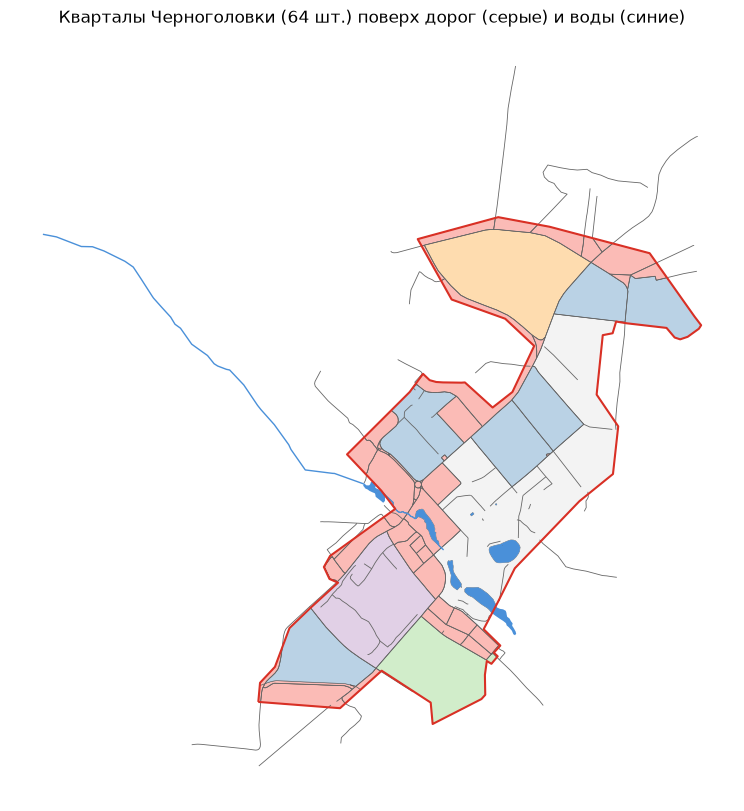

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))
blocks.plot(ax=ax, column="site_area", cmap="Pastel1", edgecolor="#555", linewidth=0.4, alpha=0.9)
roads.plot(ax=ax, color="#666", linewidth=0.6)
if len(water):
    water.plot(ax=ax, color="#4a90d9", linewidth=1)
boundaries.boundary.plot(ax=ax, color="#d93025", linewidth=1.5)
ax.set_title(f"Кварталы Черноголовки ({len(blocks)} шт.) поверх дорог (серые) и воды (синие)")
ax.set_axis_off()

### Проверка кварталов

На карте видны центр с регулярной сеткой проездов, лесопарковая окраина и Черноголовский пруд (реки Черноголовка и Пружонка образуют водоём на западе города).
Граница совпадает с городской чертой из OSM. Явно лишних участков нет, а крупные кварталы на окраинах — это лес, поля и промзоны между дорогами.

---

## ⛔ ОСТАНОВКА после подготовки кварталов

На этом месте по заданию проверяем границу и кварталы и задаём вопрос: **«Какие метрики есть в BlocksNet?»**. Ответ ниже.

## Какие метрики есть в BlocksNet

Это библиотека для анализа города «по кварталам». Помимо примера `pipeline.ipynb` в ней есть модули `analysis` (доступность, связность, разнообразие функций по Шеннону, плотность сервисов, свободные территории, центральность, социально-экономические индикаторы), `machine_learning` (предсказание землепользования и плотности) и `optimization` (подбор размещения сервисов и функций).

**Все показатели из `pipeline.ipynb`:**

| Группа | Показатель | Что означает простыми словами | Единицы | Что нужно | Что скажет о городе |
|---|---|---|---|---|---|
| Землепользование | `residential`, `business`, `recreation`, `industrial`, `transport`, `special`, `agriculture` | доля площади квартала, занятая функциональной зоной этого типа | доля 0–1 | `landuse` из OSM | где жильё, где наука и промзоны, где лес |
| Землепользование | `land_use` | преобладающая функция квартала | категория | то же | функциональная карта |
| Транспорт | матрица доступности | время пешком от центра одного квартала до центра другого | минуты | пешеходный граф | связность города |
| Здания | `footprint_area` | площадь пятен застройки | м² | здания OSM | сколько земли под домами |
| Здания | `build_floor_area` | суммарная площадь всех этажей | м² | этажность | объём застройки |
| Здания | `living_area`, `non_living_area` | жилая и нежилая площадь | м² | тип здания | жилые и нежилые кварталы |
| Здания | `number_of_floors` (через FSI/GSI) | этажность | этажи | `building:levels` | высотность |
| Здания | `population` | **оценка** числа жителей: жилая площадь / 30 м² на человека | чел. | жилая площадь | где живут люди |
| Школы | `count` | число школ в квартале | шт. | школы OSM | — |
| Школы | `capacity` | вместимость школ; где в OSM нет данных, **оценена** минимальной типовой вместимостью | мест | — | сколько мест в школах |
| Обеспеченность | `demand` | потребность: 120 мест на 1000 жителей (норматив BlocksNet) | мест | население | сколько мест нужно |
| Обеспеченность | `demand_within` / `demand_without` | спрос, удовлетворённый в пределах 15 мин пешком / дальше | мест | матрица | — |
| Обеспеченность | `demand_left` | неудовлетворённый спрос (**нехватка мест**) | мест | — | где мест не хватает |
| Обеспеченность | `capacity_within` / `capacity_without` / `capacity_left` | места, занятые «своими» (в 15 мин), «чужими», и **свободный остаток** | мест | — | где школы недогружены |
| Обеспеченность | `provision_strong` | доля спроса, закрытая в пределах нормативной доступности | 0–1 | — | строгая обеспеченность |
| Обеспеченность | `provision_weak` | доля спроса, закрытая вообще (даже дальше 15 мин) | 0–1 | — | мягкая обеспеченность |
| Обеспеченность | связи (links) | сколько детей из квартала A «прикреплено» к школе в квартале B | мест, мин | — | распределение спроса |
| Плотность | `fsi` | коэффициент плотности застройки: площадь этажей / площадь квартала | безразм. | здания | интенсивность |
| Плотность | `gsi` | коэффициент застроенности: пятна зданий / площадь квартала | 0–1 | здания | сколько земли застроено |
| Плотность | `l` | средняя этажность = FSI / GSI | этажи | — | высотность |
| Плотность | `osr` | открытое пространство на единицу площади этажей = (1 − GSI) / FSI | безразм. | — | простор / теснота |
| Плотность | `mxi` | индекс смешанности = жилая / вся площадь этажей | 0–1 | — | моно- или многофункциональность |
| Типы застройки | Spacematrix `morphotype`, `cluster` | группировка кварталов по FSI, GSI, L, MXI методом k-средних | категория | плотность | типы ткани города |
| Типы застройки | «Стрелка» `morphotype` | классификация по правилам КБ «Стрелка» (малоэтажная, среднеэтажная, многоэтажная, нежилая) | категория | плотность | — |
| Доступность | `area_accessibility` | среднее время из квартала до всей территории города, взвешенное по площади кварталов | минуты | матрица | центральные и периферийные кварталы |

Дальше выполняем расчёты этих показателей.

## 4. Землепользование

**Источник:** полигоны `landuse=*` из OSM. Правила сопоставления тегов OSM с классами BlocksNet взяты из `pipeline.ipynb` и дополнены тегами, которые встречаются в Черноголовке (сопоставление допущено вручную).
`assign_land_use` считает для каждого квартала долю площади каждой функции. Преобладающая функция назначается, если её доля достаточно велика, иначе `land_use` остаётся пустым («не определено»).

In [8]:
from blocksnet.enums import LandUse
from blocksnet.blocks.assignment import assign_land_use

functional_zones = load_or_fetch(
    "landuse", lambda: osm_features({"landuse": True}, ["landuse"]), "OpenStreetMap (landuse=*)"
)
functional_zones = functional_zones[functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])]
functional_zones = functional_zones.rename(columns={"landuse": "functional_zone"})[["functional_zone", "geometry"]]
functional_zones = functional_zones.to_crs(crs).reset_index(drop=True)
print("Теги landuse в Черноголовке:")
print(functional_zones.functional_zone.value_counts().to_string())

⬇ landuse: загружено (OpenStreetMap (landuse=*)) и сохранено в data\landuse.geojson — 105 объектов
Теги landuse в Черноголовке:
functional_zone
grass                43
residential          24
industrial           13
farmland              6
forest                5
garages               4
allotments            4
commercial            2
recreation_ground     1
retail                1
logging               1
construction          1


In [9]:
rules = {
    # из pipeline.ipynb
    "commercial": LandUse.BUSINESS, "industrial": LandUse.INDUSTRIAL, "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL, "residential": LandUse.RESIDENTIAL, "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION, "farmland": LandUse.AGRICULTURE, "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL, "forest": LandUse.RECREATION, "recreation_ground": LandUse.RECREATION,
    "religious": LandUse.SPECIAL, "flowerbed": LandUse.RECREATION, "military": LandUse.SPECIAL,
    "landfill": LandUse.TRANSPORT,
    # дополнено для Черноголовки
    "allotments": LandUse.AGRICULTURE, "orchard": LandUse.AGRICULTURE, "meadow": LandUse.RECREATION,
    "village_green": LandUse.RECREATION, "education": LandUse.BUSINESS, "institutional": LandUse.BUSINESS,
    "railway": LandUse.TRANSPORT, "depot": LandUse.TRANSPORT, "greenfield": LandUse.SPECIAL,
    "plant_nursery": LandUse.AGRICULTURE, "farmyard": LandUse.AGRICULTURE, "quarry": LandUse.INDUSTRIAL,
}

LAND_USE_COLS = [lu.value for lu in LandUse]
land_use_blocks = assign_land_use(blocks, functional_zones, rules)
land_use_blocks["land_use"] = land_use_blocks["land_use"].apply(lambda lu: lu.value if lu is not None else None)
save_geojson(land_use_blocks, RESULTS_DIR / "blocks_land_use.geojson")

lu_area = land_use_blocks.assign(area_ha=land_use_blocks.area / 1e4).groupby(
    land_use_blocks["land_use"].fillna("не определено"))["area_ha"].agg(["count", "sum"])
lu_area.columns = ["кварталов", "площадь, га"]
display(lu_area.sort_values("площадь, га", ascending=False).round(1))
display(land_use_blocks[LAND_USE_COLS + ["land_use"]].head(8).round(2))

2026-10-16 18:45:36.262 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: logging


,кварталов,"площадь, га"
land_use,,
industrial,14,488.1
residential,16,124.8
не определено,21,88.7
agriculture,4,84.9
recreation,9,7.0


,residential,business,recreation,industrial,transport,special,agriculture,land_use
0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,None
1,0.00,0.0,0.72,0.00,0.0,0.0,0.00,recreation
2,0.52,0.0,0.11,0.04,0.0,0.0,0.03,residential
3,0.00,0.0,0.26,0.00,0.0,0.0,0.00,recreation
4,0.00,0.0,0.47,0.00,0.0,0.0,0.00,recreation
5,0.00,0.0,0.00,0.00,0.0,0.0,0.67,agriculture
6,0.00,0.0,0.00,0.00,0.0,0.0,0.00,None
7,0.00,0.0,0.25,0.00,0.0,0.0,0.00,recreation


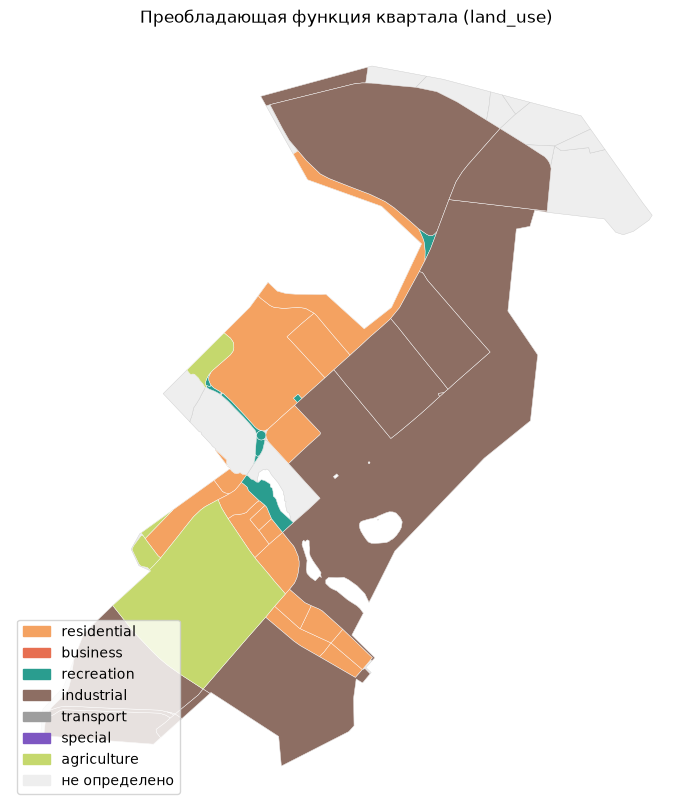

In [10]:
LU_COLORS = {"residential": "#f4a261", "business": "#e76f51", "recreation": "#2a9d8f", "industrial": "#8d6e63",
             "transport": "#9e9e9e", "special": "#7e57c2", "agriculture": "#c5d86d"}
fig, ax = plt.subplots(figsize=(10, 10))
blocks.plot(ax=ax, color="#eee", edgecolor="#ccc", linewidth=0.3)
for lu, color in LU_COLORS.items():
    sub = land_use_blocks[land_use_blocks.land_use == lu]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="#fff", linewidth=0.3, label=lu)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in LU_COLORS.values()] + [plt.Rectangle((0, 0), 1, 1, color="#eee")]
ax.legend(handles, list(LU_COLORS) + ["не определено"], loc="lower left")
ax.set_title("Преобладающая функция квартала (land_use)")
ax.set_axis_off()

## 5. Время в пути между кварталами

**Выбор графа:** готовый **пешеходный граф** OpenStreetMap: тротуары, тропинки, дворовые проезды, все линии `highway=*`, кроме автомагистралей и линий с `foot=no`. Граф собирается библиотекой OSMnx из скачанной выгрузки OSM, на каждом ребре время пешком = длина / скорость 5 км/ч (так же считает IduEdu). Интермодальный граф (пешеход + общественный транспорт) по заданию **не строим**. Для городка размером 3 × 3 км пешая доступность и так основная.
Если Overpass API работает, можно поставить `GRAPH_SOURCE = "iduedu"`, и граф скачается через `get_accessibility_graph(boundaries, "walk")` из BlocksNet.

**Способ передвижения:** пешком. **Единицы:** минуты.

Граф сохраняется в `data/graph_walk.pickle`, матрица — в `results/accessibility_matrix_walk.csv`. Сводка по кварталам (среднее и максимальное время) — в `results/blocks_accessibility.geojson`.

In [11]:
from blocksnet.relations import get_accessibility_graph, calculate_accessibility_matrix

GRAPH_FILE = DATA_DIR / "graph_walk.pickle"
if GRAPH_FILE.exists() and not REFRESH:
    graph = pickle.loads(GRAPH_FILE.read_bytes())
    print(f"✔ граф прочитан из {GRAPH_FILE}")
else:
    if GRAPH_SOURCE == "iduedu":
        graph = get_accessibility_graph(boundaries, "walk")
        graph_source = "IduEdu get_walk_graph (OpenStreetMap через Overpass API)"
    else:
        G = ox.graph_from_xml(OSM_FILE, bidirectional=True, retain_all=False)
        drop = [(u, v, k) for u, v, k, d in G.edges(keys=True, data=True)
                if str(d.get("highway")) in {"motorway", "motorway_link", "trunk", "trunk_link"} or d.get("foot") == "no"]
        G.remove_edges_from(drop)
        G = ox.truncate.largest_component(G, strongly=False)
        G = ox.project_graph(G, to_crs=crs)
        meters_per_min = WALK_SPEED_KMH * 1000 / 60
        for u, v, k, d in G.edges(keys=True, data=True):
            d["time_min"] = d["length"] / meters_per_min
        G.graph["crs"] = crs.to_epsg()
        # IduEdu (считает матрицу внутри BlocksNet) ждёт узлы с номерами 0, 1, 2, …, а не id OSM
        graph = nx.convert_node_labels_to_integers(G)
        graph_source = "OSMnx graph_from_xml по выгрузке OpenStreetMap, пешеходная сеть, 5 км/ч"
    GRAPH_FILE.write_bytes(pickle.dumps(graph))
    sources["graph_walk"] = {"source": graph_source, "downloaded": datetime.date.today().isoformat()}
    SOURCES_FILE.write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"⬇ граф загружен и сохранён в {GRAPH_FILE}")
print(f"Узлов: {graph.number_of_nodes()}, рёбер: {graph.number_of_edges()}")

⬇ граф загружен и сохранён в data\graph_walk.pickle
Узлов: 2346, рёбер: 8022


⬇ матрица рассчитана и сохранена в results\accessibility_matrix_walk.csv
Размер матрицы: (64, 64); время пешком, мин: медиана 27.9, максимум 108.6


,0,1,2,3,4,5
0,0.0,6.4,12.4,11.3,11.9,13.1
1,6.4,0.0,9.6,7.4,8.0,9.2
2,12.4,9.6,0.0,8.5,8.8,7.1
3,11.3,7.4,8.5,0.0,1.5,3.0
4,11.9,7.7,8.8,1.5,0.0,3.2
5,13.1,9.2,7.1,3.0,3.2,0.0


Повторное чтение матрицы: OK


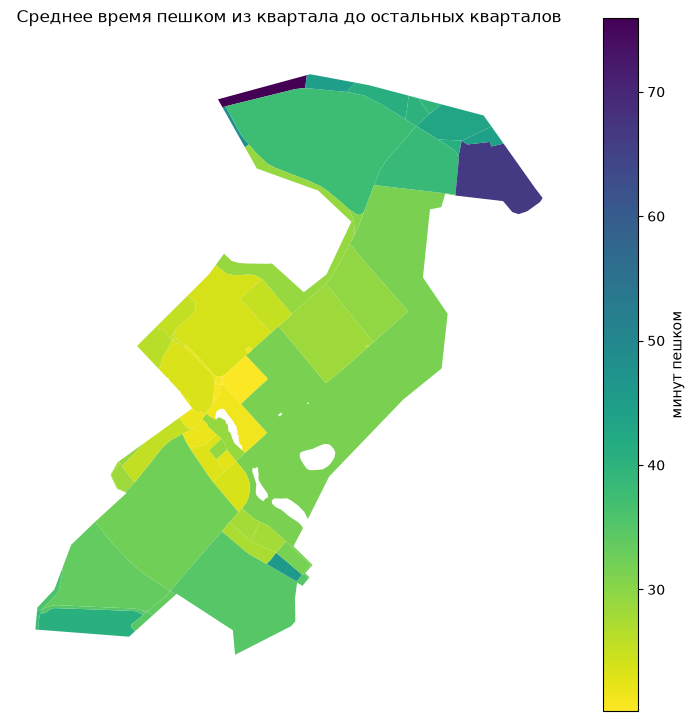

In [12]:
ACC_FILE = RESULTS_DIR / "accessibility_matrix_walk.csv"
if ACC_FILE.exists() and not REFRESH:
    acc_mx = pd.read_csv(ACC_FILE, index_col=0)
    acc_mx.columns = acc_mx.columns.astype(int)
    print(f"✔ матрица прочитана из {ACC_FILE}")
else:
    acc_mx = calculate_accessibility_matrix(blocks, graph).astype("float32")
    acc_mx.to_csv(ACC_FILE)
    print(f"⬇ матрица рассчитана и сохранена в {ACC_FILE}")

print(f"Размер матрицы: {acc_mx.shape}; время пешком, мин: медиана {np.nanmedian(acc_mx.values):.1f}, максимум {np.nanmax(acc_mx.values):.1f}")
display(acc_mx.iloc[:6, :6].round(1))

acc_blocks = blocks[["geometry"]].copy()
acc_blocks["mean_time_min"] = acc_mx.mean(axis=1)
acc_blocks["max_time_min"] = acc_mx.max(axis=1)
save_geojson(acc_blocks, RESULTS_DIR / "blocks_accessibility.geojson")

# проверка повторного чтения для следующих расчётов
check = pd.read_csv(ACC_FILE, index_col=0)
assert check.shape == acc_mx.shape, "Матрица прочитана с ошибкой"
print("Повторное чтение матрицы: OK")

ax = acc_blocks.plot("mean_time_min", cmap="viridis_r", legend=True, legend_kwds={"label": "минут пешком"})
ax.set_title("Среднее время пешком из квартала до остальных кварталов")
ax.set_axis_off()

## 6. Здания и оценка населения

**Из данных OSM:** контуры зданий, тип (`building`), этажность (`building:levels`, если указана).
**Оценено по допущениям BlocksNet (`impute_buildings`):**
- если этажность не указана — **1 этаж**;
- площадь этажей = этажность × площадь пятна;
- жилая площадь = 90 % площади этажей жилого здания;
- **население = жилая площадь / 30 м² на человека** (как в `pipeline.ipynb`).

Жилые типы: `residential`, `house`, `apartments`, `detached`, `terrace`, `dormitory` (как в `pipeline.ipynb`).
**Дополнительное допущение:** в Черноголовке 86 % зданий в OSM отмечены просто `building=yes`. Если считать жилыми только размеченные, жилых будет всего 46. Поэтому здание `yes`, стоящее внутри зоны `landuse=residential`, тоже считаем жилым (колонка `living_source`). В жилую зону попадут и гаражи с сараями, поэтому население — **модельная оценка**, а не перепись.

In [13]:
from blocksnet.preprocessing.imputing import impute_buildings
from blocksnet.blocks.aggregation import aggregate_objects

buildings_raw = load_or_fetch(
    "buildings", lambda: osm_features({"building": True}, ["building", "building:levels", "name"]),
    "OpenStreetMap (building=*)"
)
buildings = buildings_raw[buildings_raw.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(crs).reset_index(drop=True)

is_living_tags = ["residential", "house", "apartments", "detached", "terrace", "dormitory"]
buildings["is_living"] = buildings["building"].isin(is_living_tags)
# Допущение для Черноголовки: 86 % зданий в OSM размечены просто building=yes.
# Здание "yes" внутри зоны landuse=residential считаем жилым (это оценка, а не данные OSM).
residential_zone = functional_zones.loc[functional_zones.functional_zone == "residential"].union_all()
yes_in_residential = (buildings["building"] == "yes") & buildings.representative_point().within(residential_zone)
buildings["living_source"] = np.select(
    [buildings["is_living"], yes_in_residential], ["OSM", "оценка: yes в жилой зоне"], "нежилое (OSM)")
buildings.loc[yes_in_residential, "is_living"] = True

buildings["number_of_floors"] = pd.to_numeric(buildings["building:levels"], errors="coerce")
floors_source = np.where(buildings["number_of_floors"].notna(), "OSM", "оценка (1 этаж)")
living_source = buildings["living_source"].values
building_tag = buildings["building"].values

buildings = impute_buildings(buildings, default_living_demand=30)
buildings["building"], buildings["floors_source"], buildings["living_source"] = building_tag, floors_source, living_source
save_geojson(buildings, RESULTS_DIR / "buildings_imputed.geojson")

print(f"Зданий: {len(buildings)}, из них жилых: {buildings.is_living.sum()}")
print(buildings["living_source"].value_counts().to_string())
print(f"Этажность указана в OSM у {(buildings.floors_source == 'OSM').mean():.0%} зданий, остальным присвоен 1 этаж")
print(f"Оценка населения города: {buildings.population.sum():,.0f} чел. (для сравнения: по переписи 2021 г. в городе ≈ 21 тыс. жителей)".replace(",", " "))
display(buildings[["building", "living_source", "number_of_floors", "floors_source", "footprint_area", "build_floor_area",
                   "living_area", "population"]].sample(6, random_state=1).round(0))

2026-10-16 18:45:44.002 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None


2026-10-16 18:45:44.002 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None


2026-10-16 18:45:44.002 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None


2026-10-16 18:45:44.002 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None


2026-10-16 18:45:44.002 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


⬇ buildings: загружено (OpenStreetMap (building=*)) и сохранено в data\buildings.geojson — 681 объектов
Зданий: 678, из них жилых: 438
living_source
оценка: yes в жилой зоне    392
нежилое (OSM)               240
OSM                          46
Этажность указана в OSM у 54% зданий, остальным присвоен 1 этаж
Оценка населения города: 27 575 чел. (для сравнения: по переписи 2021 г. в городе ≈ 21 тыс. жителей)


,building,living_source,number_of_floors,floors_source,footprint_area,build_floor_area,living_area,population
482,yes,нежилое (OSM),1.0,оценка (1 этаж),601.0,601.0,0.0,NaN
23,yes,оценка: yes в жилой зоне,2.0,OSM,514.0,1029.0,926.0,30.0
353,apartments,OSM,10.0,OSM,334.0,3339.0,3005.0,100.0
47,apartments,OSM,9.0,OSM,561.0,5048.0,4543.0,151.0
543,yes,оценка: yes в жилой зоне,1.0,оценка (1 этаж),90.0,90.0,81.0,2.0
585,yes,оценка: yes в жилой зоне,1.0,оценка (1 этаж),306.0,306.0,276.0,9.0


2026-10-16 18:45:44.100 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-16 18:45:44.100 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


,population,footprint_area,build_floor_area,living_area,non_living_area,count
count,64.0,64.0,64.0,64.0,64.0,64.0
mean,431.0,7641.0,21701.0,13029.0,8673.0,11.0
std,1421.0,16870.0,58665.0,42757.0,20917.0,19.0
min,0.0,0.0,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0,0.0,0.0
50%,0.0,57.0,57.0,0.0,57.0,1.0
75%,102.0,5731.0,10235.0,3281.0,3100.0,17.0
max,8470.0,83367.0,328909.0,254433.0,102253.0,95.0


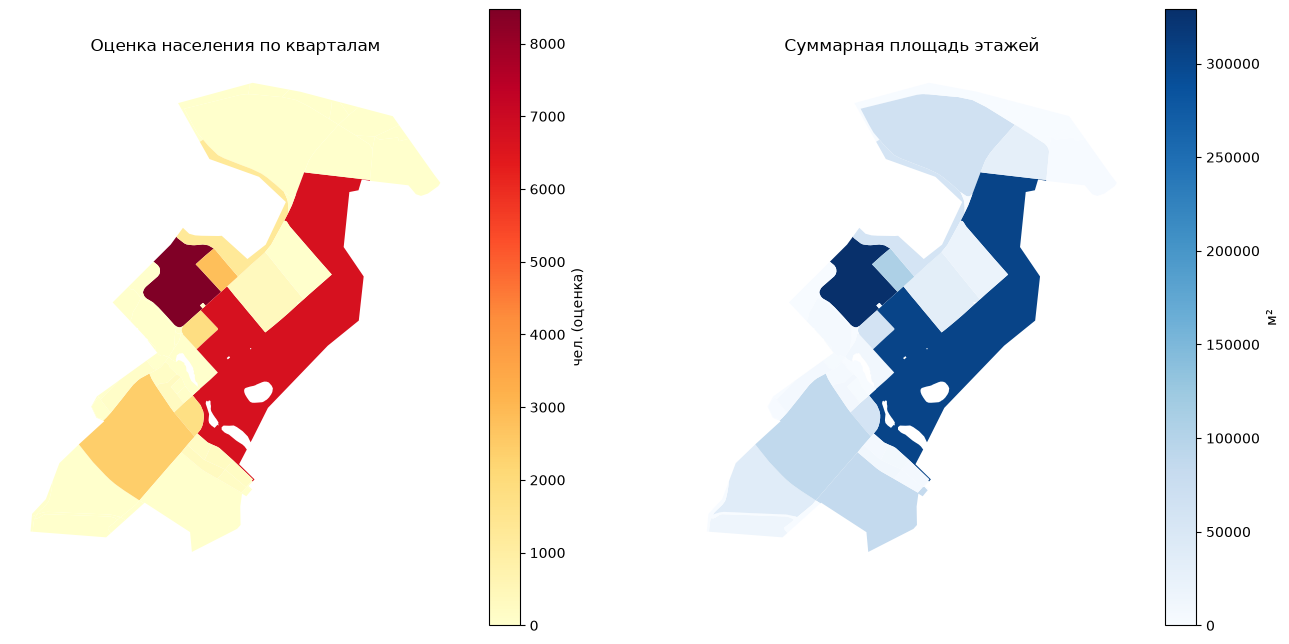

In [14]:
buildings_blocks = aggregate_objects(blocks, buildings)[0]
buildings_blocks["site_area"] = buildings_blocks.area
BUILD_COLS = ["population", "footprint_area", "build_floor_area", "living_area", "non_living_area", "count"]
BUILD_COLS = [c for c in BUILD_COLS if c in buildings_blocks.columns]
save_geojson(buildings_blocks, RESULTS_DIR / "blocks_buildings.geojson")
display(buildings_blocks[BUILD_COLS].describe().round(0))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
buildings_blocks.plot("population", cmap="YlOrRd", legend=True, ax=axes[0], legend_kwds={"label": "чел. (оценка)"})
axes[0].set_title("Оценка населения по кварталам")
buildings_blocks.plot("build_floor_area", cmap="Blues", legend=True, ax=axes[1], legend_kwds={"label": "м²"})
axes[1].set_title("Суммарная площадь этажей")
for ax in axes:
    ax.set_axis_off()

## 7. Школы

**Из данных OSM:** объекты `amenity=school` (точки и полигоны), название и вместимость (`capacity`), если она указана.
**Оценено (`impute_services`):** если вместимость не указана, BlocksNet ставит **минимальную типовую вместимость школы** из своего справочника. Колонка `capacity_source` показывает, откуда взято значение.

In [15]:
from blocksnet.preprocessing.imputing import impute_services

schools_raw = load_or_fetch(
    "schools", lambda: osm_features({"amenity": "school"}, ["amenity", "name", "capacity"]),
    "OpenStreetMap (amenity=school)"
)
schools = schools_raw.to_crs(crs).reset_index(drop=True)

# Убираем дубли: в OSM одна школа бывает нанесена дважды — территорией и зданием внутри неё.
# Объект, который лежит внутри другого школьного полигона, удаляем, а его название передаём «внешнему».
duplicates = []
for i, row in schools.iterrows():
    point = row.geometry.representative_point()
    outer = schools[(schools.index != i) & schools.contains(point) & (schools.area > row.geometry.area)]
    if len(outer):
        j = outer.index[0]
        if pd.isna(schools.loc[j, "name"]):
            schools.loc[j, "name"] = row["name"]
        duplicates.append(i)
        print(f"дубль: «{row['name']}» лежит внутри школьной территории {j} — объединены")
schools = schools.drop(index=duplicates).reset_index(drop=True)
if "capacity" not in schools.columns:
    schools["capacity"] = np.nan
schools["capacity"] = pd.to_numeric(schools["capacity"], errors="coerce")
schools["capacity_source"] = np.where(schools["capacity"].notna(), "OSM", "оценка BlocksNet")
school_names = schools["name"].values if "name" in schools.columns else [None] * len(schools)
capacity_source = schools["capacity_source"].values
schools = impute_services(schools, "school")
schools["name"], schools["capacity_source"] = school_names, capacity_source
save_geojson(schools, RESULTS_DIR / "schools_imputed.geojson")
display(schools[["name", "capacity", "capacity_source"]])

⬇ schools: загружено (OpenStreetMap (amenity=school)) и сохранено в data\schools.geojson — 6 объектов
дубль: «Школа №82» лежит внутри школьной территории 4 — объединены


,name,capacity,capacity_source
0,Школа №82 им. Ф. И. Дубовицкого,250.0,оценка BlocksNet
1,Школа №75 им. И. М. Халатникова,250.0,оценка BlocksNet
2,Веста,250.0,оценка BlocksNet
3,Школа №82,250.0,оценка BlocksNet
4,Новая Черноголовская школа,250.0,оценка BlocksNet


2026-10-16 18:45:45.213 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-16 18:45:45.214 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Школ: 5, мест всего: 1250, из них оценено: 1250


,count,capacity,capacity_imputed
0,1.0,250.0,250.0
2,1.0,250.0,250.0
25,3.0,750.0,750.0


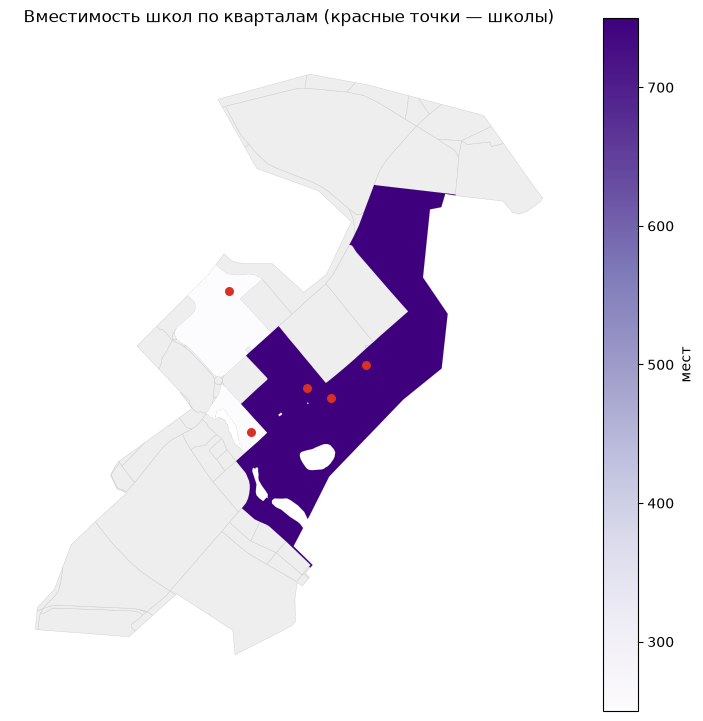

In [16]:
schools_blocks = aggregate_objects(blocks, schools)[0]
schools_blocks["capacity_imputed"] = 0.0
for _, row in schools.iterrows():
    if row.capacity_source != "OSM":
        idx = blocks.index[blocks.intersects(row.geometry.representative_point())]
        if len(idx):
            schools_blocks.loc[idx[0], "capacity_imputed"] += row.capacity
save_geojson(schools_blocks, RESULTS_DIR / "blocks_schools.geojson")
print(f"Школ: {int(schools_blocks['count'].sum())}, мест всего: {schools_blocks.capacity.sum():.0f}, из них оценено: {schools_blocks.capacity_imputed.sum():.0f}")
display(schools_blocks.loc[schools_blocks["count"] > 0, ["count", "capacity", "capacity_imputed"]])

ax = blocks.plot(color="#eee", edgecolor="#ccc", linewidth=0.3)
schools_blocks[schools_blocks.capacity > 0].plot("capacity", ax=ax, cmap="Purples", legend=True, legend_kwds={"label": "мест"})
schools.representative_point().plot(ax=ax, color="#d93025", markersize=30)
ax.set_title("Вместимость школ по кварталам (красные точки — школы)")
ax.set_axis_off()

## 8. Обеспеченность школами (конкурентная модель)

`competitive_provision` распределяет спрос жителей по школам с помощью линейной оптимизации. Ближние школы предпочтительнее, у каждой ограниченное число мест.

- **Спрос** = 120 мест на 1000 жителей, **норматив доступности** = 15 минут пешком (справочник BlocksNet).
- `provision_strong` — доля спроса квартала, закрытая школами в пределах 15 минут (строгая обеспеченность).
- `provision_weak` — доля спроса, закрытая вообще, в том числе школами дальше 15 минут (мягкая обеспеченность).
- `demand_left` — **нехватка мест**: дети, которым мест не хватило.
- `capacity_left` — **остаток мест** в школах квартала.
- Таблица связей `links` — сколько мест квартал-«потребитель» получает в квартале со школой и за сколько минут пешком.

Все значения — модельные: население оценено, вместимость частично оценена.

In [17]:
from blocksnet.config import service_types_config
from blocksnet.analysis.provision import competitive_provision, provision_strong_total, provision_weak_total

_, demand, accessibility = service_types_config["school"].values()
print(f"Норматив: {demand} мест на 1000 жителей, доступность {accessibility} мин")

prov_input = buildings_blocks[["population"]].join(schools_blocks[["capacity"]])
prov_df, links_df = competitive_provision(prov_input, acc_mx, accessibility, demand)

prov_blocks = blocks[["geometry"]].join(prov_df)
save_geojson(prov_blocks, RESULTS_DIR / "blocks_provision.geojson")

total = {
    "provision_strong (город)": provision_strong_total(prov_df),
    "provision_weak (город)": provision_weak_total(prov_df),
    "спрос, мест": prov_df["demand"].sum(),
    "нехватка (demand_left), мест": prov_df["demand_left"].sum(),
    "остаток (capacity_left), мест": prov_df["capacity_left"].sum(),
}
display(pd.Series(total).round(2).to_frame("значение"))
display(prov_df[prov_df.demand > 0].sort_values("demand", ascending=False).head(8).round(2))

2026-10-16 18:45:45.546 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame


2026-10-16 18:45:45.548 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter


2026-10-16 18:45:45.557 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


2026-10-16 18:45:45.560 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


2026-10-16 18:45:45.612 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Норматив: 120 мест на 1000 жителей, доступность 15 мин


,значение
provision_strong (город),0.38
provision_weak (город),0.38
"спрос, мест",3319.00
"нехватка (demand_left), мест",2069.00
"остаток (capacity_left), мест",0.00


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
2,1017,250,517,500,0,0,0,0,0.49,0.49
25,803,750,53,750,0,0,0,0,0.93,0.93
28,341,0,341,0,0,0,0,0,0.00,0.00
31,292,0,292,0,0,0,0,0,0.00,0.00
13,221,0,221,0,0,0,0,0,0.00,0.00
30,212,0,212,0,0,0,0,0,0.00,0.00
29,153,0,153,0,0,0,0,0,0.00,0.00
26,43,0,43,0,0,0,0,0,0.00,0.00


,from,to,seats
0,2,0,250.0


Связей «квартал → школа»: 1, из них дальше 15 мин: 0


<Axes: title={'center': 'Мягкая обеспеченность (любое время)'}, xlabel='Easting [metre]', ylabel='Northing [metre]'>

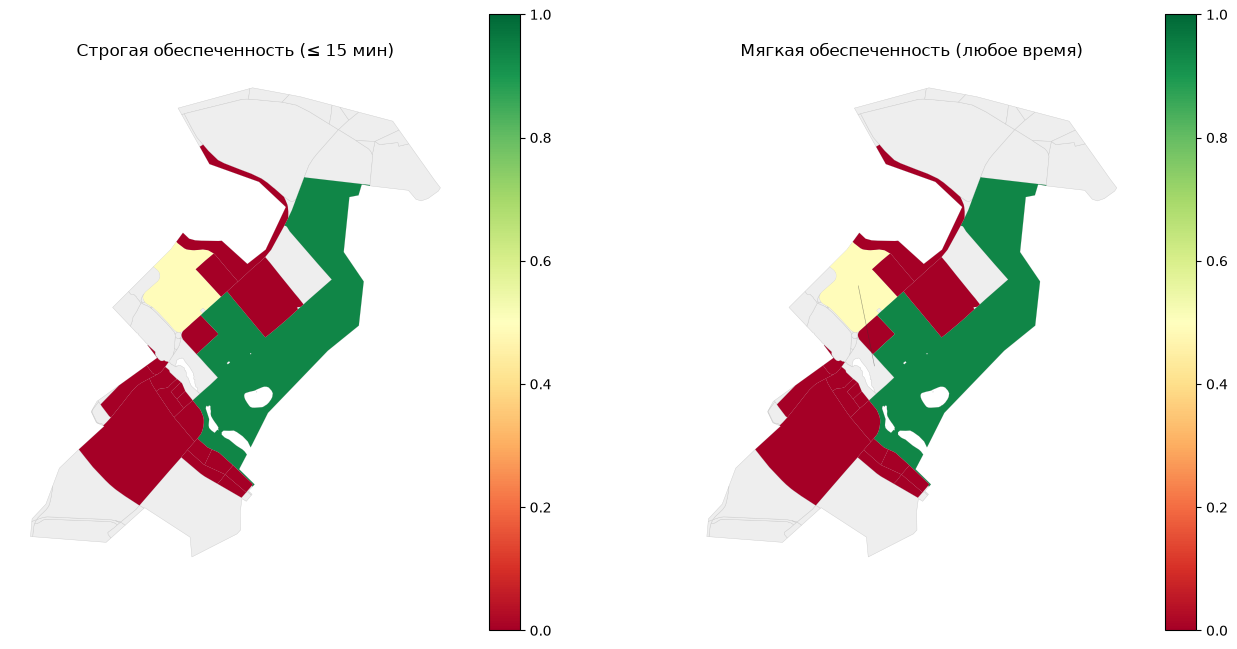

In [18]:
# source — квартал, где живут дети (спрос); target — квартал со школой; value — сколько мест «прикреплено»
links = links_df.reset_index().rename(columns={"source": "from", "target": "to", "value": "seats"})
display(links.sort_values("seats", ascending=False).head(10).round(1))
cent = blocks.representative_point()
from shapely.geometry import LineString
link_lines = gpd.GeoDataFrame(
    links,
    geometry=[LineString([cent.loc[a], cent.loc[b]]) for a, b in zip(links["from"], links["to"])],
    crs=crs,
)
link_lines["time_min"] = [acc_mx.loc[a, b] for a, b in zip(links["from"], links["to"])]
save_geojson(link_lines, RESULTS_DIR / "provision_links.geojson")
print(f"Связей «квартал → школа»: {len(link_lines)}, из них дальше {accessibility} мин: {(link_lines.time_min > accessibility).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, col, title in [(axes[0], "provision_strong", "Строгая обеспеченность (≤ 15 мин)"),
                       (axes[1], "provision_weak", "Мягкая обеспеченность (любое время)")]:
    blocks.plot(ax=ax, color="#eee", edgecolor="#ccc", linewidth=0.3)
    prov_blocks[prov_blocks.demand > 0].plot(col, ax=ax, cmap="RdYlGn", vmin=0, vmax=1, legend=True)
    ax.set_title(title)
    ax.set_axis_off()
link_lines.plot(ax=axes[1], color="#333", linewidth=0.4, alpha=0.5)

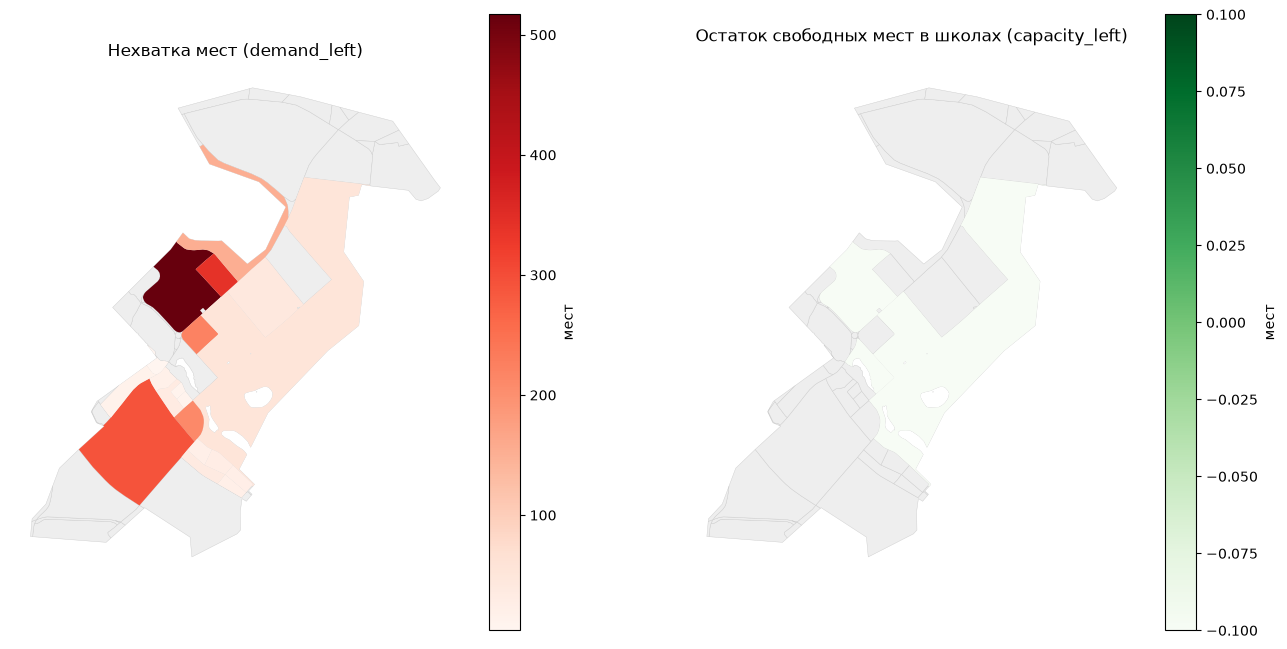

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
blocks.plot(ax=axes[0], color="#eee", edgecolor="#ccc", linewidth=0.3)
prov_blocks[prov_blocks.demand_left > 0].plot("demand_left", ax=axes[0], cmap="Reds", legend=True, legend_kwds={"label": "мест"})
axes[0].set_title("Нехватка мест (demand_left)")
blocks.plot(ax=axes[1], color="#eee", edgecolor="#ccc", linewidth=0.3)
prov_blocks[prov_blocks.capacity > 0].plot("capacity_left", ax=axes[1], cmap="Greens", legend=True, legend_kwds={"label": "мест"})
axes[1].set_title("Остаток свободных мест в школах (capacity_left)")
for ax in axes:
    ax.set_axis_off()

## 9. Плотность застройки

`calculate_density_indicators` по сумме площадей зданий в квартале считает:

- **FSI** (Floor Space Index) — площадь всех этажей / площадь квартала. Пример: FSI = 1 — на каждый м² земли приходится 1 м² пола.
- **GSI** (Ground Space Index) — доля земли под зданиями.
- **L** — средняя этажность (FSI / GSI).
- **OSR** (Open Space Ratio) — сколько незастроенной земли приходится на 1 м² пола. Чем больше, тем просторнее.
- **MXI** (Mixed-use Index) — доля жилой площади в площади этажей: 1 — только жильё, 0 — нет жилья.

,fsi,gsi,l,osr,mxi
count,64.00,64.00,33.00,33.00,33.00
mean,0.13,0.06,2.47,14.20,0.45
std,0.25,0.13,2.21,32.18,0.42
min,0.00,0.00,1.00,0.00,0.00
25%,0.00,0.00,1.01,3.87,0.00
50%,0.01,0.01,1.74,6.17,0.66
75%,0.15,0.10,1.95,10.03,0.90
max,1.20,1.00,9.00,185.21,0.90


,fsi,gsi,l,osr,mxi,population,"площадь, га"
28,1.20,0.16,7.33,0.70,0.79,2838.0,9.02
63,1.06,1.00,1.00,0.00,0.00,0.0,0.00
32,0.15,0.15,1.01,5.61,0.00,0.0,55.62
46,0.01,0.01,1.00,185.21,0.00,0.0,26.79
16,0.02,0.02,1.00,45.28,0.00,0.0,5.82


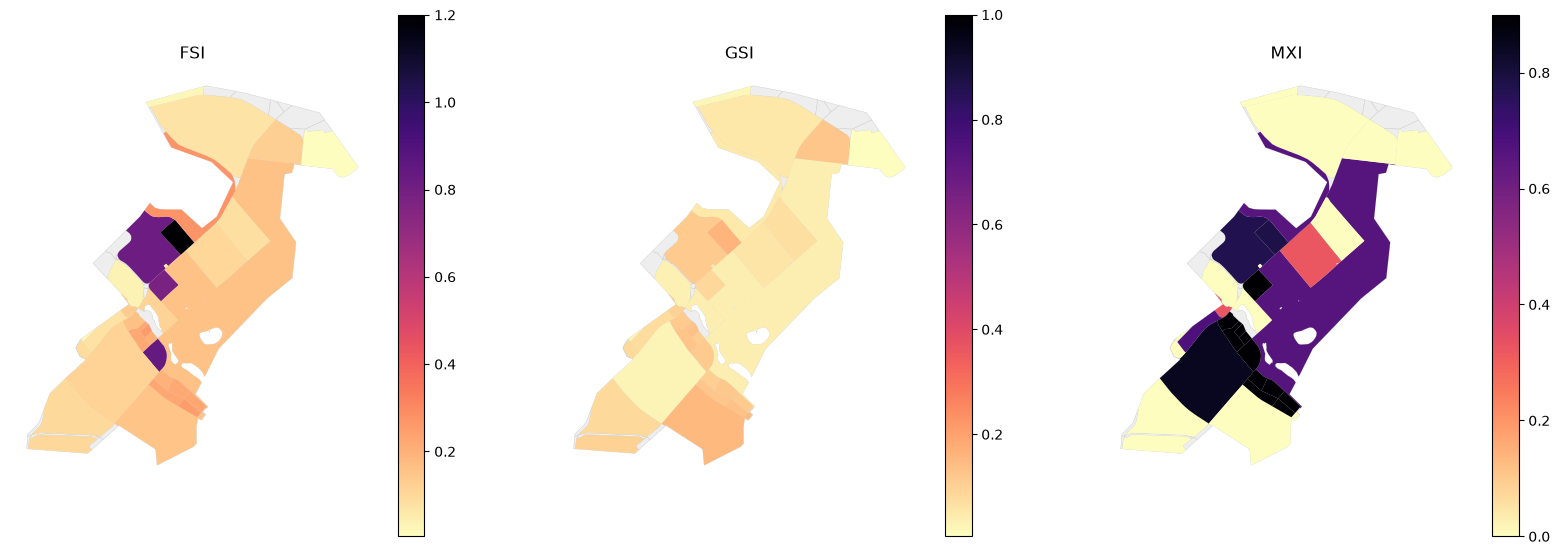

In [20]:
from blocksnet.analysis.indicators import calculate_density_indicators

density_df = calculate_density_indicators(buildings_blocks)
# OSR = (1 − GSI) / FSI: для кварталов без зданий (FSI = 0) получается деление на ноль — такие значения не определены
density_df["osr"] = density_df["osr"].replace([np.inf, -np.inf], np.nan).clip(lower=0)
DENS_COLS = [c for c in ["fsi", "gsi", "l", "osr", "mxi"] if c in density_df.columns]
density_blocks = blocks[["geometry"]].join(density_df)
save_geojson(density_blocks, RESULTS_DIR / "blocks_density.geojson")
display(density_df[DENS_COLS].describe().round(2))

# Сравнение нескольких кварталов с разными значениями
built = density_df[density_df.fsi > 0]
examples = pd.concat([built.nlargest(2, "fsi"), built.iloc[[(built.fsi - built.fsi.median()).abs().argmin()]], built.nsmallest(2, "fsi")])
examples = examples[DENS_COLS].join(buildings_blocks[["population"]]).join((blocks[["site_area"]] / 1e4).rename(columns={"site_area": "площадь, га"}))
display(examples.round(2))

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, col in zip(axes, ["fsi", "gsi", "mxi"]):
    blocks.plot(ax=ax, color="#eee", edgecolor="#ccc", linewidth=0.3)
    density_blocks[density_blocks.fsi > 0].plot(col, ax=ax, cmap="magma_r", legend=True)
    ax.set_title(col.upper())
    ax.set_axis_off()

## 10. Типы застройки

**Spacematrix** — застроенные кварталы (FSI > 0) группируются алгоритмом k-средних (по умолчанию `n_clusters = 11`) по показателям плотности. Затем каждому кластеру по средним L, FSI и MXI подбирается название морфотипа, например «low-rise low-density residential» — малоэтажная разреженная жилая застройка. Кварталы без зданий тип не получают.
**«Стрелка»** — фиксированные правила-пороги по этажности и плотности из методики КБ «Стрелка», без обучения.
Отличие: Spacematrix подстраивается под данные именно нашего города, а «Стрелка» сравнивает с одной общей шкалой для всех городов.

In [21]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
strelka_df = get_strelka_morphotypes(density_df)

morph_blocks = blocks[["geometry"]].join(spacematrix_df.add_prefix("sm_")).join(strelka_df.add_prefix("st_"))
save_geojson(morph_blocks, RESULTS_DIR / "blocks_morphotypes.geojson")
spacematrix_clusters.to_csv(RESULTS_DIR / "spacematrix_clusters.csv")

print("Spacematrix — число кварталов по морфотипам:")
display(spacematrix_df["morphotype"].value_counts().to_frame("кварталов"))
print("Характеристики кластеров Spacematrix (средние значения):")
display(spacematrix_clusters.round(2))
print("«Стрелка» — число кварталов по морфотипам:")
display(strelka_df["morphotype"].value_counts().to_frame("кварталов"))

Spacematrix — число кварталов по морфотипам:


,кварталов
morphotype,
low-rise low-density non-residential,12
low-rise low-density residential,10
mid-rise low-density residential,3
high-mid-rise low-density residential,3
low-rise low-density mixed-use,2
mid-rise low-density non-residential,1
high-mid-rise residential,1
low-rise non-residential,1


Характеристики кластеров Spacematrix (средние значения):


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,5.60,0.27,0.66,mid-rise,low-density,residential,mid-rise low-density residential
1,1.60,0.12,0.32,low-rise,low-density,mixed-use,low-rise low-density mixed-use
2,7.09,0.83,0.84,high-mid-rise,low-density,residential,high-mid-rise low-density residential
3,1.00,0.08,0.68,low-rise,low-density,residential,low-rise low-density residential
4,1.01,0.08,0.00,low-rise,low-density,non-residential,low-rise low-density non-residential
5,1.00,1.06,0.00,low-rise,None,non-residential,low-rise non-residential
6,7.33,1.20,0.79,high-mid-rise,None,residential,high-mid-rise residential
7,1.88,0.22,0.90,low-rise,low-density,residential,low-rise low-density residential
8,9.00,0.78,0.90,high-mid-rise,low-density,residential,high-mid-rise low-density residential


«Стрелка» — число кварталов по морфотипам:


,кварталов
morphotype,
low-rise non-residential,14
low-rise model,12
mid-rise,5
high-rise soviet microdistrict,1
individual residential,1


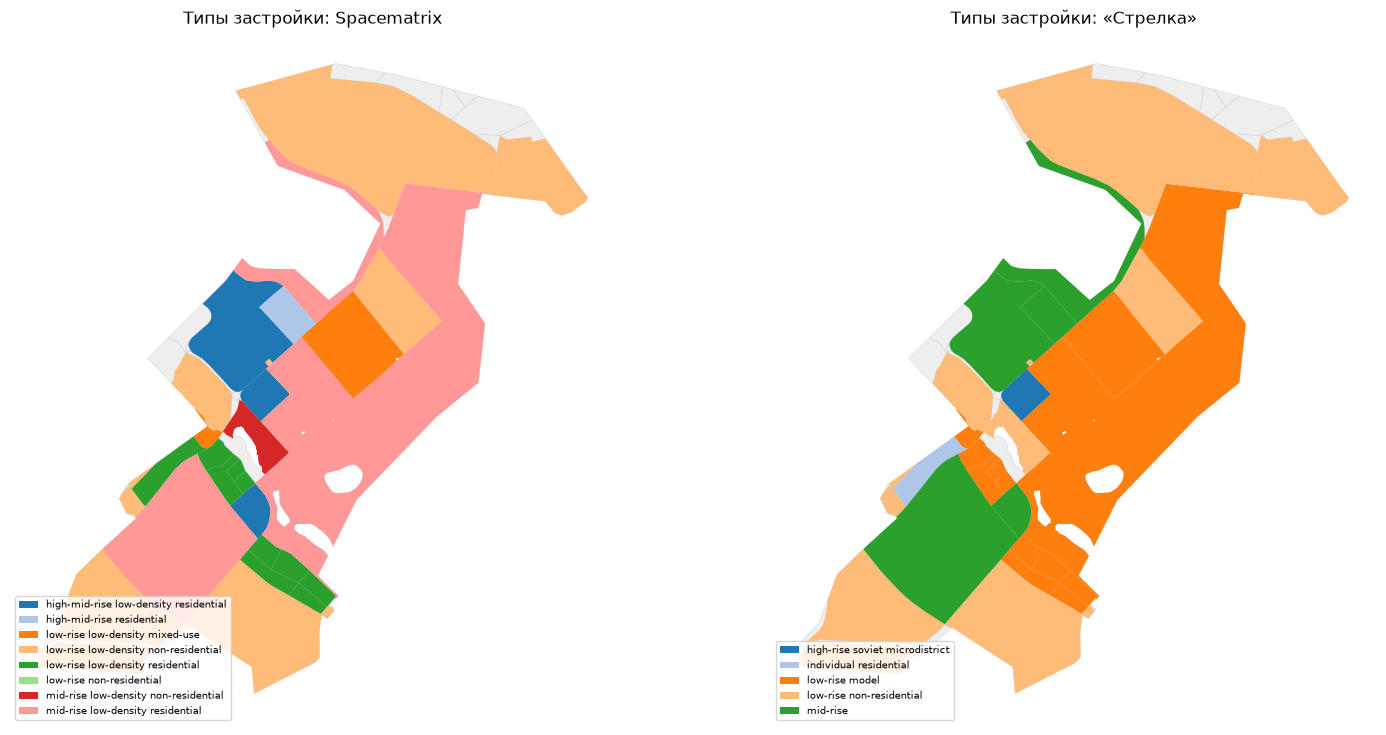

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, df, title in [(axes[0], spacematrix_df, "Spacematrix"), (axes[1], strelka_df, "«Стрелка»")]:
    blocks.plot(ax=ax, color="#eee", edgecolor="#ccc", linewidth=0.3)
    sub = blocks[["geometry"]].join(df[["morphotype"]]).dropna(subset=["morphotype"])
    sub.plot("morphotype", ax=ax, legend=True, cmap="tab20", legend_kwds={"loc": "lower left", "fontsize": 7})
    ax.set_title(f"Типы застройки: {title}")
    ax.set_axis_off()

## 11. Доступность с учётом площади

`area_accessibility` — для каждого квартала среднее время пешком до всех остальных кварталов, **взвешенное по их площади**. Большие кварталы (лес, промзона) весят больше маленьких.
Малое значение — квартал «в центре тяжести» города, большое — на периферии.

,area_accessibility
count,64.0
mean,33.5
std,9.5
min,23.8
25%,26.4
50%,31.4
75%,38.1
max,75.2


,area_accessibility,"площадь, га",land_use
27,23.8,0.2,recreation
13,23.8,7.9,residential
56,24.0,0.0,industrial
16,75.2,5.8,industrial
46,66.9,26.8,None
34,48.0,2.7,residential


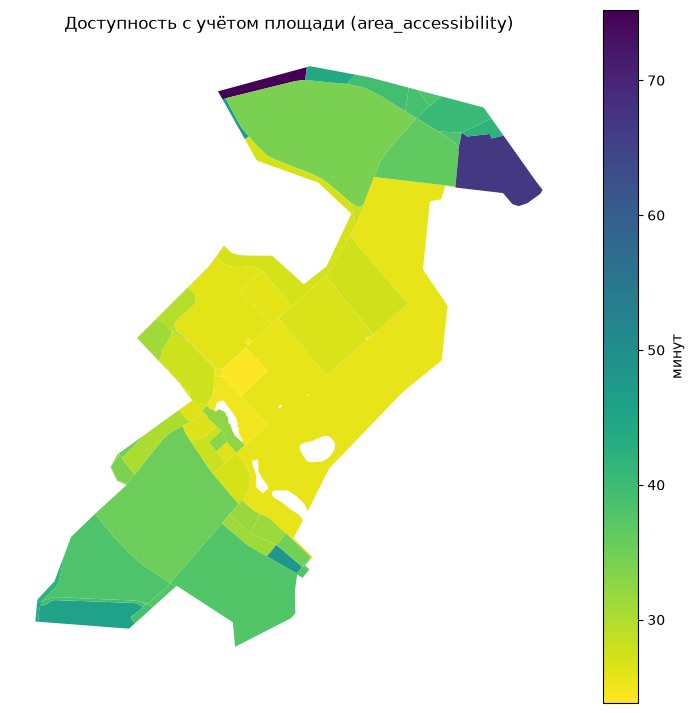

In [23]:
from blocksnet.analysis.network.accessibility import area_accessibility

area_acc = area_accessibility(acc_mx, blocks)
area_acc_blocks = blocks[["geometry"]].join(area_acc)
save_geojson(area_acc_blocks, RESULTS_DIR / "blocks_area_accessibility.geojson")
display(area_acc.describe().round(1))

ex = area_acc.join(blocks[["site_area"]] / 1e4).join(land_use_blocks[["land_use"]])
display(pd.concat([ex.nsmallest(3, "area_accessibility"), ex.nlargest(3, "area_accessibility")]).round(1)
        .rename(columns={"site_area": "площадь, га"}))

ax = area_acc_blocks.plot("area_accessibility", cmap="viridis_r", legend=True, legend_kwds={"label": "минут"})
ax.set_title("Доступность с учётом площади (area_accessibility)")
ax.set_axis_off()

## 12. Сводный слой и проверка полноты

Все показатели собираются в один файл `results/blocks_all.geojson`. Из него и других файлов `results/` скрипт `make_dashboard.py` строит `dashboard.html`.

In [24]:
all_blocks = (
    blocks[["geometry", "site_area"]]
    .join(land_use_blocks[LAND_USE_COLS + ["land_use"]])
    .join(acc_blocks[["mean_time_min", "max_time_min"]])
    .join(buildings_blocks[[c for c in BUILD_COLS]].add_prefix("bld_"))
    .join(schools_blocks[["count", "capacity", "capacity_imputed"]].add_prefix("sch_"))
    .join(prov_df.drop(columns=[c for c in ["population", "capacity"] if c in prov_df.columns]).add_prefix("prov_"))
    .join(density_df[DENS_COLS])
    .join(spacematrix_df[["cluster", "morphotype"]].add_prefix("sm_"))
    .join(strelka_df[["morphotype"]].add_prefix("st_"))
    .join(area_acc)
)
all_blocks["block_id"] = all_blocks.index
save_geojson(all_blocks, RESULTS_DIR / "blocks_all.geojson")

summary = {
    "кварталов": len(all_blocks),
    "площадь города, км²": round(boundaries.area.sum() / 1e6, 2),
    "население (оценка), чел.": int(all_blocks.bld_population.sum()),
    "школ": int(all_blocks.sch_count.sum()),
    "мест в школах (оценка)": int(all_blocks.sch_capacity.sum()),
    "provision_strong (город)": round(provision_strong_total(prov_df), 2),
    "provision_weak (город)": round(provision_weak_total(prov_df), 2),
    "медианное время пешком между кварталами, мин": round(float(np.nanmedian(acc_mx.values)), 1),
    "средний FSI застроенных кварталов": round(float(density_df.loc[density_df.fsi > 0, "fsi"].mean()), 2),
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.Series(summary).to_frame("значение"))

checklist = pd.DataFrame([
    ("Землепользование (доли и land_use)", "раздел 4", "blocks_land_use.geojson"),
    ("Матрица времени пешком", "раздел 5", "accessibility_matrix_walk.csv"),
    ("Здания и население", "раздел 6", "blocks_buildings.geojson"),
    ("Школы и вместимость", "раздел 7", "blocks_schools.geojson"),
    ("Обеспеченность и связи", "раздел 8", "blocks_provision.geojson, provision_links.geojson"),
    ("Плотность FSI/GSI/L/OSR/MXI", "раздел 9", "blocks_density.geojson"),
    ("Spacematrix и «Стрелка»", "раздел 10", "blocks_morphotypes.geojson, spacematrix_clusters.csv"),
    ("Доступность с учётом площади", "раздел 11", "blocks_area_accessibility.geojson"),
], columns=["показатель", "где в ноутбуке", "файл"])
checklist["файл есть"] = checklist["файл"].apply(lambda s: all((RESULTS_DIR / f.strip()).exists() for f in s.split(",")))
display(checklist)

,значение
кварталов,64.00
"площадь города, км²",8.05
"население (оценка), чел.",27575.00
школ,5.00
мест в школах (оценка),1250.00
provision_strong (город),0.38
provision_weak (город),0.38
"медианное время пешком между кварталами, мин",27.90
средний FSI застроенных кварталов,0.26


,показатель,где в ноутбуке,файл,файл есть
0,Землепользование (доли и land_use),раздел 4,blocks_land_use.geojson,True
1,Матрица времени пешком,раздел 5,accessibility_matrix_walk.csv,True
2,Здания и население,раздел 6,blocks_buildings.geojson,True
3,Школы и вместимость,раздел 7,blocks_schools.geojson,True
4,Обеспеченность и связи,раздел 8,"blocks_provision.geojson, provision_links.geojson",True
5,Плотность FSI/GSI/L/OSR/MXI,раздел 9,blocks_density.geojson,True
6,Spacematrix и «Стрелка»,раздел 10,"blocks_morphotypes.geojson, spacematrix_cluste...",True
7,Доступность с учётом площади,раздел 11,blocks_area_accessibility.geojson,True


## Выводы

Выводы сформулированы по результатам расчётов выше. Цифры подставлены из сохранённых файлов.

In [25]:
lu_share = land_use_blocks.assign(a=land_use_blocks.area).groupby(land_use_blocks.land_use.fillna("не определено"))["a"].sum()
lu_share = (lu_share / lu_share.sum() * 100).round(0)
print("Доли площади города по преобладающей функции, %:")
print(lu_share.sort_values(ascending=False).to_string())
print()
print(f"Строгая обеспеченность школами (≤ {accessibility} мин пешком): {provision_strong_total(prov_df):.0%}; мягкая: {provision_weak_total(prov_df):.0%}")
print(f"Нехватка мест: {prov_df.demand_left.sum():.0f}, остаток свободных мест: {prov_df.capacity_left.sum():.0f}")
print(f"Самый частый тип Spacematrix: {spacematrix_df.morphotype.value_counts().idxmax()}")
print(f"Самый частый тип «Стрелки»: {strelka_df.morphotype.value_counts().idxmax()}")

Доли площади города по преобладающей функции, %:
land_use
industrial       62.0
residential      16.0
agriculture      11.0
не определено    11.0
recreation        1.0

Строгая обеспеченность школами (≤ 15 мин пешком): 38%; мягкая: 38%
Нехватка мест: 2069, остаток свободных мест: 0
Самый частый тип Spacematrix: low-rise low-density non-residential
Самый частый тип «Стрелки»: low-rise non-residential


### Что мы узнали о Черноголовке

1. **Функции.** Больше всего площади (≈ 62 %) у кварталов с преобладающей функцией «industrial». В OSM так размечены территории институтов научного центра РАН и производственные зоны на востоке города. Жилые кварталы занимают ≈ 16 % площади и вытянуты полосой с северо-запада на юго-восток. На юго-западе — сельскохозяйственные земли и садовые участки.
2. **Население.** По модели в городе ≈ 27,6 тыс. человек, тогда как перепись 2021 г. даёт ≈ 21 тыс. Перебор возникает из-за допущения «здание `yes` в жилой зоне — жилое»: в жилые попадают и гаражи. Жители сосредоточены в нескольких многоэтажных микрорайонах: в одном квартале по модели живёт около 8,5 тыс. человек.
3. **Пешая доступность.** Медианное время пешком между кварталами ≈ 28 минут. Доступность с учётом площади — от ≈ 24 мин в центре до ≈ 75 мин на окраинах. Город компактный, но кварталы крупные, поэтому время между их центрами получается заметным.
4. **Школы.** По модели обеспеченность 38 %, строгая и мягкая совпадают. Все 1250 мест (5 школ по 250 мест) заняты детьми из ближайших кварталов в пределах 15 минут, и на остальные кварталы мест не остаётся (нехватка ≈ 2000 мест). Главная причина — в OSM нет вместимости школ, и BlocksNet подставил минимальную типовую (250 мест). Реальные школы крупнее, поэтому вывод о нехватке **нельзя считать фактом**. Это показывает, как сильно результат зависит от восстановленных данных.
5. **Плотность и типы застройки.** Город разреженный: средний FSI застроенных кварталов ≈ 0,26, максимальный ≈ 1,2 в центральном микрорайоне со средней этажностью ≈ 7. Spacematrix и «Стрелка» сходятся: преобладает малоэтажная нежилая застройка (институты, промзоны), а жильё — это несколько средне- и многоэтажных микрорайонов и немного индивидуальной застройки. Spacematrix делит кварталы тоньше, потому что кластеры строятся по данным самого города.

### Ограничения

- Кварталы крупнее реальных: по тегам `pipeline.ipynb` внутриквартальные проезды (`service`) не режут территорию.
- Пешеходный граф не учитывает закрытые территории институтов, рельеф и переходы.
- Этажность есть у 54 % зданий, остальным присвоен 1 этаж. Население и вместимость школ — модельные оценки.
- Данные OSM на дату загрузки (см. `data/sources.json`), © участники OpenStreetMap, ODbL.